# Reviewer checks: are the synergies informative beyond cohort membership, and are synthetic features collinear with their constituents?

Reviewer 2, comment 2 (and Reviewer 1, comment 2): does a stable pair carry signal beyond the two constituents, or is it a pair of two individually informative, correlated features? Reviewer 2, comment 5: collinearity between synthetic features and their constituents in the combined model. Reviewer 1, comment 5: cohort-adjusted models.

Two analyses:
1. **Cohort-adjusted logistic regression with likelihood-ratio tests** for the stable pairs (Results 2): on the pooled 15 two-class CRC cohorts, `y ~ cohort + log x1 + log x2` versus `y ~ cohort + log x1 + log x2 + log x1 × log x2` (interaction LRT), and `y ~ cohort` versus `y ~ cohort + log x1 + log x2` (does the pair carry signal beyond cohort membership?).
2. **Collinearity**: Spearman correlation between each stable synthetic feature (LR or GM, the encoding used in Figure 3) and its two constituents, pooled over the same cohorts.

Inputs: `../R2_classification_performance/final_synthetic_features_table.csv`, `../R2_classification_performance/meta_results_all_pairs.csv`, prepared cohort matrices. Outputs: `stable_pairs_lrt.tsv`, `collinearity.tsv`, `r5_numbers.tsv`.

In [1]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr, chi2
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings('ignore')
RES = '../M2_loco_crc_pipeline/results'
PREP = '../M1_data_preparation/prepared_data'
numbers = []
def note(claim, value, source): numbers.append({'section': 'R5', 'claim': claim, 'value': value, 'source': source}); print(f'{claim}: {value}')


In [3]:
# 1. Cohort-adjusted logistic regression + LRT for the stable pairs
fin = pd.read_csv('../R2_classification_performance/final_synthetic_features_table.csv')
meta = pd.read_csv('../R2_classification_performance/meta_results_all_pairs.csv')[['data_type', 'feature_pair', 'feature_type']]
fin = fin.merge(meta.rename(columns={'data_type': 'Data Type', 'feature_pair': 'Feature'}), on=['Data Type', 'Feature'], how='left')
ALL = sorted({os.path.basename(p)[2:].rsplit('_', 1)[0] for p in glob.glob(f'{PREP}/X_*_taxa.tsv')})
_cache = {}
def load(dt):
    if dt in _cache: return _cache[dt]
    Xs, ys, cs = [], [], []
    for c in ALL:
        xf, yf = f'{PREP}/X_{c}_{dt}.tsv', f'{PREP}/y_{c}_{dt}.tsv'
        if not (os.path.exists(xf) and os.path.exists(yf)): continue
        X = pd.read_csv(xf, sep='\t', index_col=0); y = pd.read_csv(yf, sep='\t', index_col=0).squeeze().astype(int)
        if y.nunique() < 2: continue                      # single-class cohorts cannot inform a case-control model
        X = X.div(X.sum(axis=1), axis=0); common = X.index.intersection(y.index)
        Xs.append(X.loc[common]); ys.append(y.loc[common]); cs.append(pd.Series(c, index=common))
    X = pd.concat(Xs).fillna(0); _cache[dt] = (X, pd.concat(ys), pd.concat(cs)); return _cache[dt]
def lrt(ll0, ll1, df): return chi2.sf(2 * (ll1 - ll0), df)
def fit(y, Xd):
    try: return sm.Logit(y, Xd).fit(disp=0, maxiter=200, method='bfgs').llf
    except Exception: return np.nan
rows = []
for _, r in fin.iterrows():
    X, y, c = load(r['Data Type']); f1, f2 = r['Feature1'], r['Feature2']
    if f1 not in X.columns or f2 not in X.columns: rows.append({'Data Type': r['Data Type'], 'Feature': r['Feature'], 'note': 'feature missing'}); continue
    x1, x2 = np.log10(X[f1] + 1e-6), np.log10(X[f2] + 1e-6)
    case = (y == 0).astype(int)                            # 0 = CRC in the prepared labels
    C = pd.get_dummies(c, drop_first=True).astype(float)
    base = sm.add_constant(C)
    add = base.assign(x1=x1.values, x2=x2.values)
    inter = add.assign(x1x2=(x1 * x2).values)
    l0, l1, l2 = fit(case, base), fit(case, add), fit(case, inter)
    rows.append({'Data Type': r['Data Type'], 'Feature': r['Feature'], 'Feature1': f1, 'Feature2': f2, 'n_samples': len(y), 'n_cohorts': c.nunique(),
                 'p_pair_beyond_cohort': lrt(l0, l1, 2), 'p_interaction': lrt(l1, l2, 1), 'llf_cohort': l0, 'llf_additive': l1, 'llf_interaction': l2})
lr = pd.DataFrame(rows)
ok = lr.p_interaction.notna()
lr.loc[ok, 'q_interaction'] = multipletests(lr.loc[ok, 'p_interaction'], method='fdr_bh')[1]
lr.loc[ok, 'q_pair_beyond_cohort'] = multipletests(lr.loc[ok, 'p_pair_beyond_cohort'], method='fdr_bh')[1]
lr.to_csv('stable_pairs_lrt.tsv', sep='\t', index=False)
note('Stable pairs informative beyond cohort membership (LRT additive vs cohort-only, BH q < 0.05)', f'{(lr.q_pair_beyond_cohort < 0.05).sum()}/{ok.sum()}', 'R5 stable_pairs_lrt.tsv')
note('Stable pairs with a significant multiplicative interaction term (LRT interaction vs additive, BH q < 0.05)', f'{(lr.q_interaction < 0.05).sum()}/{ok.sum()}', 'R5 stable_pairs_lrt.tsv')
lr.sort_values('p_interaction').head(15)


Stable pairs informative beyond cohort membership (LRT additive vs cohort-only, BH q < 0.05): 235/235
Stable pairs with a significant multiplicative interaction term (LRT interaction vs additive, BH q < 0.05): 123/235


,Data Type,Feature,Feature1,Feature2,n_samples,n_cohorts,p_pair_beyond_cohort,p_interaction,llf_cohort,llf_additive,llf_interaction,q_interaction,q_pair_beyond_cohort
226,taxa,Peptostreptococcus_stomatis__Solobacterium_SGB...,Peptostreptococcus_stomatis,Solobacterium_SGB6833,2577,15,3.479070e-86,1.313327e-10,-1517.036299,-1320.260746,-1299.616447,1.850974e-08,5.487124e-86
149,combined,Fusobacterium_nucleatum__Megasphaera_micronuci...,Fusobacterium_nucleatum,Megasphaera_micronuciformis,2577,15,2.633819e-91,1.912792e-10,-1517.036299,-1308.469490,-1288.192606,1.850974e-08,4.512716e-91
24,combined,Peptostreptococcus_stomatis__Streptococcus_sp_...,Peptostreptococcus_stomatis,Streptococcus_sp_263_SSPC,2577,15,1.000202e-80,2.362946e-10,-1517.036299,-1332.829693,-1312.759264,1.850974e-08,1.305819e-80
63,taxa,Peptostreptococcus_SGB749__Peptostreptococcus_...,Peptostreptococcus_SGB749,Peptostreptococcus_stomatis,2577,15,1.231166e-86,1.367147e-09,-1517.036299,-1319.221943,-1300.864381,8.031989e-08,1.968191e-86
191,combined,Fusobacterium_nucleatum__PWY-702:_L-methionine...,Fusobacterium_nucleatum,PWY-702:_L-methionine_biosynthesis_II,2577,15,7.969507e-92,2.396980e-09,-1517.036299,-1307.274093,-1289.463627,1.126581e-07,1.560695e-91
22,combined,Mogibacterium_diversum__Parvimonas_micra,Mogibacterium_diversum,Parvimonas_micra,2577,15,1.205797e-79,1.305337e-08,-1517.036299,-1335.319217,-1319.157531,4.275346e-07,1.431122e-79
119,taxa,Mogibacterium_diversum__Parvimonas_micra,Mogibacterium_diversum,Parvimonas_micra,2577,15,1.401073e-79,1.446565e-08,-1517.036299,-1335.469315,-1319.407430,4.275346e-07,1.646261e-79
212,combined,Fusobacterium_nucleatum__PWY-I9:_L-cysteine_bi...,Fusobacterium_nucleatum,PWY-I9:_L-cysteine_biosynthesis_VI_(from_L-met...,2577,15,1.563691e-91,1.455437e-08,-1517.036299,-1307.948105,-1291.892159,4.275346e-07,2.963447e-91
231,taxa,Lancefieldella_parvula__Parvimonas_micra,Lancefieldella_parvula,Parvimonas_micra,2577,15,4.080660e-81,3.604107e-08,-1517.036299,-1331.933165,-1316.757368,9.410723e-07,5.448608e-81
89,combined,Fusobacterium_nucleatum__TRNA-CHARGING-PWY:_tR...,Fusobacterium_nucleatum,TRNA-CHARGING-PWY:_tRNA_charging,2577,15,4.969741e-92,1.063787e-07,-1517.036299,-1306.801838,-1292.674694,2.499900e-06,1.033530e-91


Stable synthetic features: median |Spearman| with the more correlated constituent (and share > 0.9): 0.79 (19 %)
Stable pairs: median Spearman correlation between the two constituents: 0.08


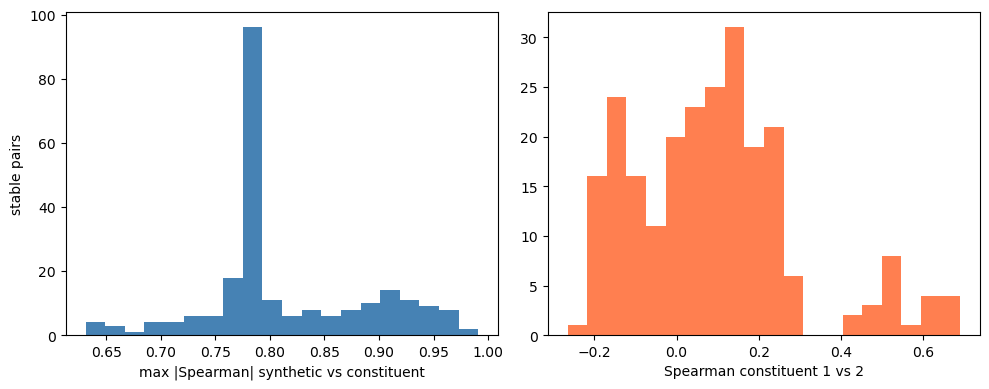

In [4]:
# 2. Collinearity of the stable synthetic features with their constituents
rows = []
for _, r in fin.iterrows():
    X, y, c = load(r['Data Type']); f1, f2 = r['Feature1'], r['Feature2']
    if f1 not in X.columns or f2 not in X.columns: continue
    a, b = X[f1].values + 1e-9, X[f2].values + 1e-9
    ft = r['feature_type'] if isinstance(r.get('feature_type'), str) else 'GM'
    s = np.log(a / b) if ft == 'LR' else np.sqrt(a * b)
    rows.append({'Data Type': r['Data Type'], 'Feature': r['Feature'], 'transformation': ft,
                 'spearman_synthetic_vs_f1': spearmanr(s, a).correlation, 'spearman_synthetic_vs_f2': spearmanr(s, b).correlation,
                 'spearman_f1_vs_f2': spearmanr(a, b).correlation})
col = pd.DataFrame(rows); col['max_abs_corr_with_constituent'] = col[['spearman_synthetic_vs_f1', 'spearman_synthetic_vs_f2']].abs().max(axis=1)
col.to_csv('collinearity.tsv', sep='\t', index=False)
note('Stable synthetic features: median |Spearman| with the more correlated constituent (and share > 0.9)',
     f'{col.max_abs_corr_with_constituent.median():.2f} ({100 * (col.max_abs_corr_with_constituent > 0.9).mean():.0f} %)', 'R5 collinearity.tsv')
note('Stable pairs: median Spearman correlation between the two constituents', f'{col.spearman_f1_vs_f2.median():.2f}', 'R5 collinearity.tsv')
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(col.max_abs_corr_with_constituent, bins=20, color='steelblue'); ax[0].set_xlabel('max |Spearman| synthetic vs constituent'); ax[0].set_ylabel('stable pairs')
ax[1].hist(col.spearman_f1_vs_f2, bins=20, color='coral'); ax[1].set_xlabel('Spearman constituent 1 vs 2')
plt.tight_layout(); plt.savefig('collinearity.png', dpi=150); plt.show()
pd.DataFrame(numbers).to_csv('r5_numbers.tsv', sep='\t', index=False, mode='w')
